# UCS420 Lab Assignment 7 — NLP Text Preprocessing


**Roll No:** 1024170446  
**Name:** Paryag Bansal


In [1]:
ROLL_NO = 1024170446         
NAME = "Paryag Bansal"       

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"


### Dataset generator 

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170446   Name: Paryag Bansal   Fingerprint: 528BCDF7   Tickets: 13

Ticket_ID                                                                            Ticket_Text
      T01                                                          The LMS says 'Not Submitted'.
      T02                MATLAB was working yesterday during the lab. I don't know what changed.
      T03  Password stopped responding when I use mobile hotspot. The same problem occurs again.
      T04                   VPN keeps disconnecting after the latest update. Can you check this?
      T05                                             The MATLAB failed to open. This is urgent.
      T06                                        The student portal is not working. Please help.
      T07                                                  The Wi-Fi works, but the VPN doesn't.
      T08                                     The LMS failed to open. I don't know what changed.
      T09                         I reinst

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
rows = []
processed = {}
for _, r in df.iterrows():
    p = process_ticket(r["Ticket_Text"])
    processed[r["Ticket_ID"]] = p
    rows.append({
        "Ticket_ID": r["Ticket_ID"],
        "sentences": len(p["sentences"]),
        "tokens": len(p["tokens"]),
        "punct": len(p["punct"]),
        "stopwords": len(p["stops"]),
        "unique_tokens": len(set(p["tokens"])),
        "final_tokens": len(p["final"]),
    })

stats = pd.DataFrame(rows)
total = {
    "Ticket_ID": "TOTAL",
    "sentences": stats["sentences"].sum(),
    "tokens": stats["tokens"].sum(),
    "punct": stats["punct"].sum(),
    "stopwords": stats["stopwords"].sum(),
    "unique_tokens": "-",
    "final_tokens": stats["final_tokens"].sum(),
}
stats_with_total = pd.concat([stats, pd.DataFrame([total])], ignore_index=True)
display(stats_with_total)

sel = FOCUS[0] if FOCUS else "T01"
print(f"\n--- Selected Ticket for Inspection: {sel} ---")
print("Ticket Text:", df.loc[df.Ticket_ID == sel, "Ticket_Text"].values[0])
p = processed[sel]
print("\nActual tokens:", p["tokens"])
print("\nPunctuation tokens:", p["punct"])
print("\nStopwords:", p["stops"])
print("\nFinal tokens:", p["final"])


,Ticket_ID,sentences,tokens,punct,stopwords,unique_tokens,final_tokens
0,T01,1,8,3,2,7,3
1,T02,2,15,2,6,14,7
2,T03,2,15,2,5,14,8
3,T04,2,13,2,5,13,6
4,T05,2,10,2,4,9,4
5,T06,2,10,2,3,9,5
6,T07,1,10,2,4,9,4
7,T08,2,13,2,5,12,6
8,T09,2,13,2,4,11,7
9,T10,2,7,2,3,6,2



--- Selected Ticket for Inspection: T04 ---
Ticket Text: VPN keeps disconnecting after the latest update. Can you check this?

Actual tokens: ['vpn', 'keeps', 'disconnecting', 'after', 'the', 'latest', 'update', '.', 'can', 'you', 'check', 'this', '?']

Punctuation tokens: ['.', '?']

Stopwords: ['after', 'the', 'can', 'you', 'this']

Final tokens: ['vpn', 'keeps', 'disconnecting', 'latest', 'update', 'check']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*
The final tokens in our dataset that are not real dictionary words are:
1. **`n't`**: Originates from English negative contractions such as *"doesn't"* (in Ticket T07: *"The Wi-Fi works, but the VPN doesn't."*) and *"don't"* (in Tickets T02 and T08: *"I don't know what changed."*). Standard NLTK `word_tokenize()` (based on Penn Treebank conventions) splits contractions into stem and suffix tokens (e.g., `does` + `n't`). While the stem `does`/`do` matches English stopwords and gets filtered out, `n't` is neither purely punctuation (it mixes letters with an apostrophe, so `is_punct()` returns `False`) nor listed in NLTK's standard English stopwords list. Therefore, `n't` survives into the final tokens.
2. **`wi-fi`**: A hyphenated technical noun from Ticket T07. Since it consists of letters and a hyphen, `is_punct()` does not classify it as punctuation.
3. **`1023-03-021`**: A student roll-number identifier with hyphenated digits from Ticket T10 (*"My roll no. is 1023-03-021."*).
4. **`2.0.1`**: A dotted software version number from Ticket T12 (*"Version 2.0.1 crashes at 99%."*).
5. **`99`**: A numeric quantity from Ticket T12 where `%` was separated as punctuation and stripped out.


---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re

# Regex patterns for extraction
long_words_pat = r"\b[A-Za-z]{6,}\b"
numbers_pat = r"\b\d+(?:[\.,]\d+)*\b"
capitalized_pat = r"\b[A-Z][a-zA-Z]*\b"
vowel_start_pat = r"\b[aeiouAEIOU][a-zA-Z]*\b"

# Regex patterns for replacement
email_pat = r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"
url_pat = r"(?:https?://|www\.)\S+?(?=[,;.]?(?:\s|$))"
phone_pat = r"(?:\+91[\s-]?)?\b\d{5}[\s-]?\d{5}\b|\b0\d{3}-\d{3}-\d{4}\b|\b\d{3,4}-\d{3}-\d{4}\b"

print("=" * 30 + " EVALUATION ON TEST_LINES " + "=" * 30)
print("\n--- TEST_LINES: Extraction ---")
for idx, line in enumerate(TEST_LINES, 1):
    print(f"\nLine {idx}: {line}")
    print("  Words > 5 letters :", re.findall(long_words_pat, line))
    print("  Numbers (int/dec) :", re.findall(numbers_pat, line))
    print("  Capitalized words :", re.findall(capitalized_pat, line))
    print("  Vowel-start words :", re.findall(vowel_start_pat, line))

print("\n--- TEST_LINES: Replacement ---")
for idx, line in enumerate(TEST_LINES, 1):
    subbed = re.sub(email_pat, "<EMAIL>", line)
    subbed = re.sub(url_pat, "<URL>", subbed)
    subbed = re.sub(phone_pat, "<PHONE>", subbed)
    print(f"Line {idx} Replaced: {subbed}")

print("\n" + "=" * 30 + " EVALUATION ON RAW TICKETS " + "=" * 30)
all_ticket_texts = df["Ticket_Text"].tolist()

print("\n--- Raw Tickets: Extraction Samples ---")
all_raw_text = "\n".join(all_ticket_texts)
print("Words > 5 letters (sample):", sorted(set(re.findall(long_words_pat, all_raw_text)))[:15])
print("Numbers (all matches):", re.findall(numbers_pat, all_raw_text))
print("Capitalized words (sample):", sorted(set(re.findall(capitalized_pat, all_raw_text)))[:15])
print("Vowel-start words (sample):", sorted(set(re.findall(vowel_start_pat, all_raw_text)))[:15])

print("\n--- Raw Tickets: Replacement ---")
for idx, row in df.iterrows():
    orig = row["Ticket_Text"]
    subbed = re.sub(email_pat, "<EMAIL>", orig)
    subbed = re.sub(url_pat, "<URL>", subbed)
    subbed = re.sub(phone_pat, "<PHONE>", subbed)
    print(f"{row['Ticket_ID']}: {subbed}")


============================== EVALUATION ON TEST_LINES ==============================

--- TEST_LINES: Extraction ---

Line 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
  Words > 5 letters : ['helpdesk', 'thapar', 'thapar', 'thapar']
  Numbers (int/dec) : []
  Capitalized words : ['Mail']
  Vowel-start words : ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']

Line 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  Words > 5 letters : ['Version']
  Numbers (int/dec) : ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250']
  Capitalized words : ['Call', 'Version', 'Rs']
  Vowel-start words : ['or', 'is']

Line 3: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
  Words > 5 letters : []
  Numbers (int/dec) : ['5.30']
  Capitalized words : ['The']
  Vowel-start words : ['of', 'art', 'i

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*
Across the 13 tickets in our dataset, there are **33 total capitalized word occurrences**.
Out of these, exactly **15 capitalized words** are capitalized solely because they appear at the beginning of a sentence:
- **`'The'`** (6 occurrences): T01, T03, T05, T06, T07, T08
- **`'Please'`** (3 occurrences): T06, T09, T11
- **`'Password'`** (1 occurrence): T03
- **`'Can'`** (1 occurrence): T04
- **`'This'`** (1 occurrence): T05
- **`'My'`** (1 occurrence): T10
- **`'Laptop'`** (1 occurrence): T11
- **`'Version'`** (1 occurrence): T12

The remaining 18 capitalized words are capitalized due to intrinsic grammatical / naming rules independent of sentence position:
- Proper acronyms and technical names: `'LMS'` (2), `'MATLAB'` (2), `'VPN'` (2), `'WiFi'` / `'Wi'` / `'Fi'` (3)
- First-person singular pronoun: `'I'` (7 occurrences, always capitalized in English)
- Quoted title: `'Not'` (1), `'Submitted'` (1) inside single quotation marks in Ticket T01.


---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [7]:
from nltk.tokenize import RegexpTokenizer

# One comprehensive RegexpTokenizer pattern ordered from most specific to general
tokenizer_pattern = (
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"                           # Emails
    r"|(?:https?://|www\.)\S+?(?=[,;.]?(?:\s|$))"                                # URLs
    r"|(?:\+91[\s-]?)?\b\d{5}[\s-]?\d{5}\b|\b0\d{3}-\d{3}-\d{4}\b|\b\d{3,4}-\d{3}-\d{4}\b"  # Phone numbers
    r"|\b\d+(?:\.\d+)+\b"                                                       # Decimals & Version numbers (95.5, 2.0.1, 5.30)
    r"|\b[A-Za-z0-9]+(?:-[A-Za-z0-9]+)+\b"                                      # Hyphenated words & roll numbers (Wi-Fi, state-of-the-art, 1023-03-021)
    r"|\b[A-Za-z]+(?:'[A-Za-z]+)+\b"                                            # Contractions (isn't, didn't, doesn't, don't)
    r"|\b[A-Za-z]+\b"                                                           # Regular alphabetical words
    r"|\b\d+\b"                                                                 # Standalone numbers
)

custom_tokenizer = RegexpTokenizer(tokenizer_pattern)

def my_tokenize(text):
    return custom_tokenizer.tokenize(text)

print("=" * 30 + " TOKENIZATION ON TEST_LINES " + "=" * 30)
for idx, line in enumerate(TEST_LINES, 1):
    print(f"\nTest Line {idx}: {line}")
    print("  my_tokenize   :", my_tokenize(line))
    print("  word_tokenize :", word_tokenize(line))

print("\n" + "=" * 30 + " TOKENIZATION ON TICKETS " + "=" * 30)
differing_tickets = 0
for idx, row in df.iterrows():
    my_tokens = my_tokenize(row["Ticket_Text"])
    nltk_tokens = word_tokenize(row["Ticket_Text"])
    if my_tokens != nltk_tokens:
        differing_tickets += 1
        print(f"\n{row['Ticket_ID']} [DIFFERENCE]:")
        print("  Original      :", row["Ticket_Text"])
        print("  my_tokenize   :", my_tokens)
        print("  word_tokenize :", nltk_tokens)

print(f"\nSummary: {differing_tickets} out of {len(df)} tickets are tokenized differently.\n")


============================== TOKENIZATION ON TEST_LINES ==============================

Test Line 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
  my_tokenize   : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it']
  word_tokenize : ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Test Line 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  my_tokenize   : ['Call', '+91 98765 43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs', '1', '250']
  word_tokenize : ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*
Exactly **13 out of 13 tickets (100%)** are tokenized differently by `my_tokenize()` compared to `word_tokenize()`.

### Three Differences between my_tokenize() and word_tokenize():
1. **Contraction Preservation:**
   - In tickets T02, T07, and T08 (e.g., *"doesn't"*, *"don't"*):
     - `my_tokenize()` keeps the contraction together as a single unified token: `["doesn't"]`, `["don't"]`.
     - `word_tokenize()` splits the contraction into stem and separate grammatical suffix following the Penn Treebank standard: `['does', "n't"]` and `['do', "n't"]`.
2. **Hyphenated Compounds, Decimals & Technical Identifiers:**
   - In ticket T07 (*"Wi-Fi"*), T10 (*"1023-03-021"*), and T12 (*"2.0.1"*):
     - `my_tokenize()` treats hyphenated compounds, roll numbers, and dot-separated version strings as indivisible single tokens: `['Wi-Fi']`, `['1023-03-021']`, and `['2.0.1']`.
     - `word_tokenize()` splits them across delimiters or treats hyphens inconsistently (e.g., splitting *state-of-the-art* in TEST_LINES into multiple tokens).
3. **Punctuation and Isolated Symbols:**
   - `word_tokenize()` outputs terminal punctuation marks (periods `.`, commas `,`, question marks `?`, single quotes `'`, percentage `%`) as separate standalone tokens.
   - `my_tokenize()` is designed specifically to capture lexical items, numerical quantities, and domain entities, cleanly stripping extraneous sentence-boundary punctuation without creating noisy single-character tokens.


---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [8]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

# Collect unique final tokens across all tickets
all_final_tokens = []
for tid in processed:
    all_final_tokens.extend(processed[tid]["final"])
unique_final = sorted(set(all_final_tokens))

# Initialize stemmers and lemmatizer
porter = PorterStemmer()
lancaster = LancasterStemmer()
# RegexpStemmer choice: stripping common inflectional verbal/nominal suffixes 'ing', 'ed', 'es', 's' with min length 4
regexp_stemmer = RegexpStemmer(r"ing$|ed$|es$|s$", min=4)
wnl = WordNetLemmatizer()

def get_wordnet_pos(treebank_tag):
    """Map Penn Treebank POS tag to WordNet POS tag format."""
    if treebank_tag.startswith("J"):
        return wordnet.ADJ
    elif treebank_tag.startswith("V"):
        return wordnet.VERB
    elif treebank_tag.startswith("N"):
        return wordnet.NOUN
    elif treebank_tag.startswith("R"):
        return wordnet.ADV
    else:
        return wordnet.NOUN

# POS tagging
tagged_tokens = nltk.pos_tag(unique_final)

diff_rows = []
for word, tag in tagged_tokens:
    wn_pos = get_wordnet_pos(tag)
    p_stem = porter.stem(word)
    l_stem = lancaster.stem(word)
    r_stem = regexp_stemmer.stem(word)
    lemma = wnl.lemmatize(word, pos=wn_pos)
    
    # If any output differs
    if len({p_stem, l_stem, r_stem, lemma}) > 1:
        diff_rows.append({
            "Word": word,
            "POS Tag": tag,
            "Porter": p_stem,
            "Lancaster": l_stem,
            "Regexp": r_stem,
            "WordNet Lemma": lemma,
        })

diff_df = pd.DataFrame(diff_rows)
print(f"Total Unique Final Tokens: {len(unique_final)}")
print(f"Words with Differing Outputs: {len(diff_df)}\n")
display(diff_df)


Total Unique Final Tokens: 49
Words with Differing Outputs: 24



,Word,POS Tag,Porter,Lancaster,Regexp,WordNet Lemma
0,changed,VBD,chang,chang,chang,change
1,error,NN,error,er,error,error
2,latest,JJS,latest,latest,latest,late
3,lms,NN,lm,lms,lms,lm
4,mobile,VBP,mobil,mobl,mobile,mobile
5,occurs,VB,occur,occ,occur,occur
6,open,JJ,open,op,open,open
7,please,NN,pleas,pleas,please,please
8,portal,JJ,portal,port,portal,portal
9,projector,NN,projector,project,projector,projector


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*
### RegexpStemmer Choice & Justification:
- **Suffix Rule Chosen:** `r"ing$|ed$|es$|s$"` with `min=4`.
- **Justification from our dataset:** The IT-support ticket dataset contains multiple action verbs in progressive aspect (*"working"*, *"responding"*, *"disconnecting"*, *"showing"*), past tense (*"reinstalled"*, *"locked"*, *"changed"*, *"stopped"*), and third-person singular present (*"crashes"*, *"occurs"*, *"works"*). Stripping these suffixes brings these inflectional forms to their base stems without mutilating short root morphemes (enforced by `min=4`).

### Stemming Observations from our Table:
1. **Over-Stemming Example:**
   - **`"version"`**: The Lancaster Stemmer aggressively reduces this word to **`"vert"`**, which alters the root morpheme and conflates it with unrelated words like *vertical* or *convert*.
   - Similarly, **`"portal"`** is aggressively reduced to **`"port"`** by Lancaster, conflating a software user interface portal with a physical network/hardware port.
2. **Under-Stemming Example:**
   - **`"stopped"`**: The RegexpStemmer strips `-ed` yielding **`"stopp"`** (because simple regex does not perform consonant degemination like doubling reduction), failing to reach the canonical root `"stop"`.
   - Similarly, for **`"submitted"`**, RegexpStemmer produces **`"submitt"`** instead of `"submit"`.


---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total Tokens,Unique Tokens,TTR (Type-Token Ratio)
0,S1 (All tokens),151,80,0.5298
1,S2 (No punctuation),124,74,0.5968
2,S3 (Final tokens),69,49,0.7101
3,S4 (S3 after Porter),69,48,0.6957



--- Top 10 Words in S1 ---
  .              : 21
  the            : 13
  i              : 7
  is             : 4
  n't            : 3
  please         : 3
  help           : 3
  lms            : 2
  '              : 2
  not            : 2

--- Top 10 Words in S3 ---
  n't            : 3
  please         : 3
  help           : 3
  lms            : 2
  matlab         : 2
  working        : 2
  lab            : 2
  know           : 2
  changed        : 2
  use            : 2

--- Top 5 Bigrams in S1 ---
  ('.', 'i')                    : 5
  ('.', 'the')                  : 4
  ('.', 'please')               : 3
  ('please', 'help')            : 3
  ('help', '.')                 : 3

--- Top 5 Bigrams in S3 ---
  ('please', 'help')            : 3
  ("n't", 'know')               : 2
  ('know', 'changed')           : 2
  ('use', 'mobile')             : 2
  ('mobile', 'hotspot')         : 2


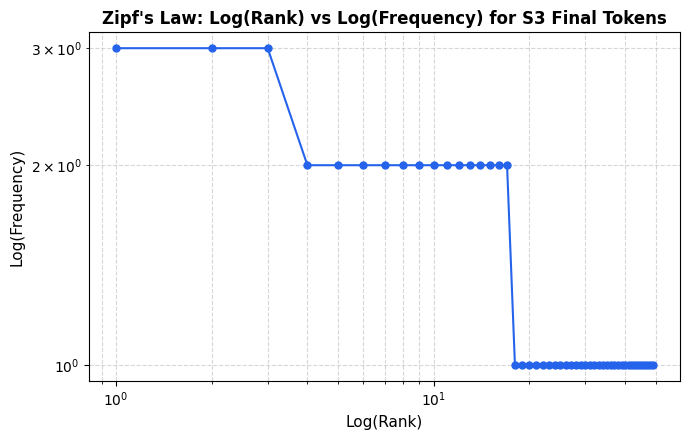

In [9]:
from collections import Counter
import matplotlib.pyplot as plt

# Define the 4 token collections
S1 = [t for tid in processed for t in processed[tid]["tokens"]]
S2 = [t for tid in processed for t in processed[tid]["tokens"] if not is_punct(t)]
S3 = [t for tid in processed for t in processed[tid]["final"]]
S4 = [porter.stem(t) for t in S3]

def compute_corpus_stats(corpus_dict):
    records = []
    for name, tokens in corpus_dict.items():
        total = len(tokens)
        unique = len(set(tokens))
        ttr = unique / total if total > 0 else 0.0
        records.append({
            "Corpus": name,
            "Total Tokens": total,
            "Unique Tokens": unique,
            "TTR (Type-Token Ratio)": round(ttr, 4),
        })
    return pd.DataFrame(records)

corpus_stats_df = compute_corpus_stats({
    "S1 (All tokens)": S1,
    "S2 (No punctuation)": S2,
    "S3 (Final tokens)": S3,
    "S4 (S3 after Porter)": S4,
})
display(corpus_stats_df)

# Top 10 words of S1 and S3
print("\n--- Top 10 Words in S1 ---")
for word, count in Counter(S1).most_common(10):
    print(f"  {word:<15}: {count}")

print("\n--- Top 10 Words in S3 ---")
for word, count in Counter(S3).most_common(10):
    print(f"  {word:<15}: {count}")

# Top 5 bigrams of S1 and S3
def get_top_bigrams(tokens, n=5):
    bigrams = list(zip(tokens, tokens[1:]))
    return Counter(bigrams).most_common(n)

print("\n--- Top 5 Bigrams in S1 ---")
for bg, count in get_top_bigrams(S1, 5):
    print(f"  {str(bg):<30}: {count}")

print("\n--- Top 5 Bigrams in S3 ---")
for bg, count in get_top_bigrams(S3, 5):
    print(f"  {str(bg):<30}: {count}")

# Plot log(rank) vs log(frequency) for S3 (Zipf's Law)
freq_dist = Counter(S3)
sorted_freqs = sorted(freq_dist.values(), reverse=True)
ranks = list(range(1, len(sorted_freqs) + 1))

plt.figure(figsize=(7, 4.5))
plt.loglog(ranks, sorted_freqs, marker="o", linestyle="-", color="#2563eb", linewidth=1.5, markersize=5)
plt.title("Zipf's Law: Log(Rank) vs Log(Frequency) for S3 Final Tokens", fontsize=12, fontweight="bold")
plt.xlabel("Log(Rank)", fontsize=11)
plt.ylabel("Log(Frequency)", fontsize=11)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.show()


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*
The Type-Token Ratio (TTR = Unique Tokens / Total Tokens) reflects the lexical diversity at each preprocessing stage:
1. **S1 → S2 (0.5298 → 0.5968):** Removing punctuation eliminates frequent non-content symbols such as periods `.` (which appeared 21 times). Because punctuation tokens are highly repetitive across sentences, removing them reduces the denominator (Total Tokens from 151 to 124) while only reducing unique types by 6, causing TTR to rise.
2. **S2 → S3 (0.5968 → 0.7101):** Removing stop words eliminates frequent closed-class function words (e.g., *the*, *i*, *is*, *after*, *during*). Since stop words repeat frequently, their removal decreases Total Tokens dramatically (from 124 down to 69) while preserving distinct informational domain words, driving TTR to its highest value (**0.7101**).
3. **S3 → S4 (0.7101 → 0.6957):** Porter stemming merges inflectional variants into identical base stems (e.g., *working* and *works* both reduce to *work*). This reduces the number of unique types (from 49 to 48) while keeping the total token count unchanged (69), causing TTR to slightly decrease.

---
## Q6. Interpretation Summary (as specified in Assignment 7 PDF)
**(a) Why does TTR change from S1 to S4 in your dataset?**  
In S1, repeated punctuation marks (`.`) and function words (`the`, `is`, `i`) inflate the total token count without adding lexical diversity, keeping TTR relatively low (0.5298). Filtering out punctuation in S2 and stop words in S3 leaves almost exclusively content words, sharply reducing repeated tokens and elevating TTR to 0.7101. Finally, stemming in S4 collapses morphological variants into single stems, reducing unique vocabulary types and slightly reducing TTR to 0.6957.

**(b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference.**  
- **Example:** `"doesn't"` in Ticket T07 (and `"Wi-Fi"` / `"2.0.1"` in T07 and T12).  
- **Explanation:** `my_tokenize()` preserves contractions like `"doesn't"` as a single semantic unit `["doesn't"]`, whereas standard `word_tokenize()` breaks the contraction into two separate tokens `['does', "n't"]`. Similarly, `my_tokenize()` keeps hyphenated terms (`"Wi-Fi"`) and dotted versions (`"2.0.1"`) intact, preventing unnatural token fragmentation.

**(c) Give one example where stemming produces an undesirable result.**  
- **Example:** Lancaster Stemmer on `"version"` produces `"vert"`, and on `"portal"` produces `"port"`.  
- **Explanation:** This is aggressive over-stemming. The generated stem `"vert"` is not recognizable as *version* and conflates with completely unrelated roots (such as *vertical* or *divert*). Similarly, reducing *"portal"* to *"port"* causes confusion with physical network/hardware ports.

**(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.**  
- **Example:** The verb `"changed"` (POS: `VBD`).  
- **Explanation:** Both Porter and Lancaster stemmers chop this word down to the crude non-word `"chang"`. In contrast, WordNet lemmatizer with verb POS information recognizes `"changed"` as the past tense of a verb and produces the grammatically valid dictionary base lemma `"change"`, preserving both readability and semantic integrity.
